# 📘 Logistic Regression

## 🔍 What is Logistic Regression?

Logistic regression is a **statistical method** used for **binary classification problems**, where the target/output variable is **categorical** and typically has **two possible values**, such as:
- Yes / No
- Success / Failure
- 1 / 0

It is used when the data is **linearly separable**, meaning there exists a linear boundary between the two classes.

---

## 🧠 Key Concepts

- Logistic regression models the relationship between **independent variables** and the **log-odds of the dependent variable**.
- It uses the **sigmoid function** to convert the linear output into a **probability** between **0 and 1**.
- The model predicts the **probability of belonging to a particular class**.

---

## 🧮 Sigmoid Function

The **sigmoid function** is defined as:

\[
\text{sigmoid}(z) = \frac{1}{1 + e^{-z}}
\]

Where:
- `z` is the linear combination of input features (`z = w₀ + w₁x₁ + w₂x₂ + ...`)
- Output range: **(0, 1)**
- Threshold: **0.5** – used to classify into class 0 or 1

---

### 📉 Sigmoid Curve (S-shaped)
                      ...............

                    /          

                   /

       .......... /.......... 0.5 Threshold Value

                 /

                /

               /

     .........


- The curve flattens near 0 and 1
- Allows mapping of any real value to a probability

---

## 📚 Beyond Binary: Multi-Class Logistic Regression

Logistic Regression can be extended for **multi-class problems** using the **Softmax Function**.

### 🔢 Softmax Function:

\[
\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{k} e^{z_j}}
\]

Where:
- \( z_i \) is the score (logit) for class \( i \)
- \( k \) is the number of classes
- Converts logits into **probabilities that sum to 1**

---

## 🧩 Types of Logistic Regression

| Type                         | Description                                                   |
|------------------------------|---------------------------------------------------------------|
| **Binary Logistic Regression**     | Two outcome classes (e.g., Yes/No)                          |
| **Multinomial Logistic Regression** | More than two unordered outcome classes                    |
| **Ordinal Logistic Regression**    | More than two **ordered** outcome classes (e.g., Low/Medium/High) |

---

## 💼 Applications of Logistic Regression

1. **Medical Diagnosis**  
   - Predicting presence or absence of disease based on symptoms, tests

2. **Marketing Analytics**  
   - Predicting whether a customer will purchase a product

3. **Credit Scoring**  
   - Estimating loan default risk from financial history

4. **Spam Detection**  
   - Classifying emails as spam or not spam

5. **Customer Churn**  
   - Predicting whether a customer will leave a service

---

## ✅ Summary

- Logistic Regression is a powerful and interpretable **classification algorithm**
- Works best for **linearly separable** problems
- Extended to multi-class using **Softmax**
- Uses **sigmoid** to convert linear output into probabilities




-----

### Practical implementation of the logistic regression algorithm

#### Logistic Regression Binary classification - Binary input

In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
# dataset = pd.read_csv(r'C:\Users\junai\Desktop\coding\ML\subscription_data.csv')
# the above file was having very less data accuracy .50
dataset = pd.read_csv(r'C:\Users\junai\Desktop\coding\ML\accurate_subscription_data.csv')
dataset.head()

,Age,EstimatedSalary,Purchased
0,56,62841,0
1,46,30104,0
2,32,69911,1
3,60,48190,0
4,25,42357,0


In [35]:
# wil use only two columns, 'Age' and 'Subscribed' because we want to implement a binary classification
dataset.drop(columns=['EstimatedSalary'], inplace=True)
dataset.head()

,Age,Purchased
0,56,0
1,46,0
2,32,1
3,60,0
4,25,0


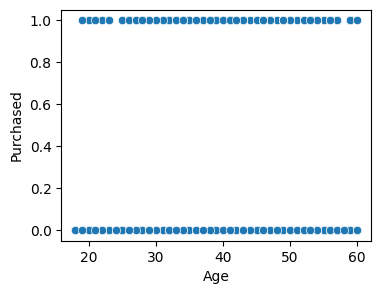

In [36]:
# now lets see if the data is applicable for logistic regression
plt.figure(figsize=(4, 3))
sns.scatterplot(x='Age', y='Purchased', data=dataset)
plt.show()


In [37]:
# we can see that the data is lionearly separable, so we can use logistic regression
# seperating data into dependent and independent variables
X = dataset[['Age']]
y = dataset['Purchased']

In [38]:
# splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
from sklearn.linear_model import LogisticRegression

In [40]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

In [41]:
lr.score(X_test, y_test)*100

61.0

In [42]:
# the accuracy is low but we can make it better later 

# lets test the model and predict the results
lr.predict([[40]])  # predicting for a person with age 40

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

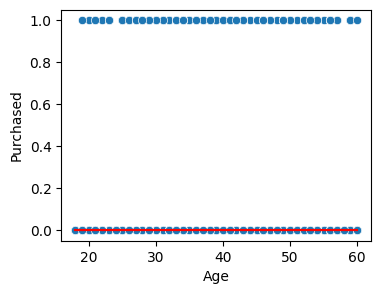

In [45]:
# now creating prediction line

plt.figure(figsize=(4, 3))
sns.scatterplot(x='Age', y='Purchased', data=dataset)
sns.lineplot(x = "Age" , y= lr.predict(X), data=dataset, color='red')
plt.show()


In [46]:
# since the data was not accurate we are not able to see S shaped or Z shaped line

-----

### Practical implementation of the logistic regression algorithm

#### Logistic Regression Binary classification - Mutiple input

In [1]:
# we willl predict tha placemnt of student based on cgpa and score of test exam
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:

# lets load the dataset
dataset = pd.read_csv(r'C:\Users\junai\Desktop\coding\ML\student_placement_data.csv')
dataset.head(10)

,cgpa,score,placed
0,6.87,7.79,1
1,9.75,7.14,1
2,8.66,6.24,1
3,7.99,8.26,1
4,5.78,7.74,1
5,5.78,5.65,0
6,5.29,8.64,1
7,9.33,8.29,1
8,8.01,8.80,1
9,8.54,7.90,1


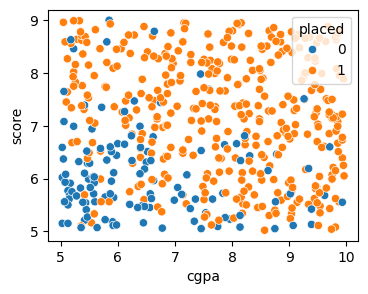

In [5]:
# lets create a graph and see if the data is applicable for logistic regression i.e its linearly separable
plt.figure(figsize=(4, 3))
sns.scatterplot(x='cgpa', y='score', hue='placed', data=dataset)
plt.show()

In [6]:
# the data is not that much linearly separable but we can still use logistic regression
# seperating data into dependent and independent variables
X = dataset[['cgpa', 'score']]
Y = dataset['placed']

In [7]:
# lets split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [9]:
# now lets create a logistic regression model
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

In [10]:
lr.score(X_test, y_test)*100

88.0

In [12]:
# 88 * is  goood accuracy for this dataset

# now lets predict the results
lr.predict([[8.0, 90]])  # predicting for a student with cgpa

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1], dtype=int64)

In [13]:
# 1 indicated that the student is placed and 0 indicates that the student is not placed

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


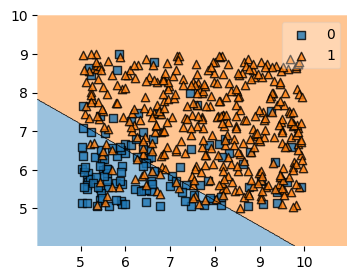

In [15]:
# now we want to see the decision boundary using ml extend library
from mlxtend.plotting import plot_decision_regions

plt.figure(figsize=(4, 3))
plot_decision_regions(X.to_numpy(), Y.to_numpy(), clf=lr)
plt.show()

In [16]:
# the algroithm used in this model is
# y = 1 / (1 + e^(-z))
# where z = b0 + b1*x1 + b2*x2 + ... +
# bN*xN
# where b0 is the intercept and b1, b2, ..., bN are the coefficients of the features x1, x2, ..., xN
# this is the logistic regression equation
# the coefficients can be accessed using the coef_ attribute of the model
print("Coefficients:", lr.coef_)
print("Intercept:", lr.intercept_)  
# the coefficients are the weights assigned to each feature in the model
# the intercept is the bias term in the model
# we can see that the coefficients are not that much high, so the model is not overfitting
# we can also see that the intercept is negative, which means that the model is biased towards
# predicting 0 (not placed) when the features are low
# we can also see that the coefficients are positive, which means that the model is biased towards
# predicting 1 (placed) when the features are high
# we can also see that the coefficients are not that much high, so the model is not overfitting


Coefficients: [[0.78494227 1.18948193]]
Intercept: [-12.47046756]


-----

### Practical implementation of the logistic regression algorithm

#### Logistic Regression  - Polynomial input

In [2]:
# logistic regression in binary classification using polynomial input is used when the dataset is not properly linearly seperable , then we change the logistic regresstion into polynomial feature 

# this file was having very less linearly seperable data so will use it  ,accurcy was around 50
# dataset = pd.read_csv(r'C:\Users\junai\Desktop\coding\ML\subscription_data.csv')

# we will first test it without polynomial feature and the after using polynomial feature to see whats diffrence  

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# load data set
dataset = pd.read_csv(r'C:\Users\junai\Desktop\coding\ML\subscription_data.csv')
dataset.head()

,Age,EstimatedSalary,Purchased
0,56,115235,1
1,46,89740,1
2,32,131352,1
3,60,81617,1
4,25,31896,0


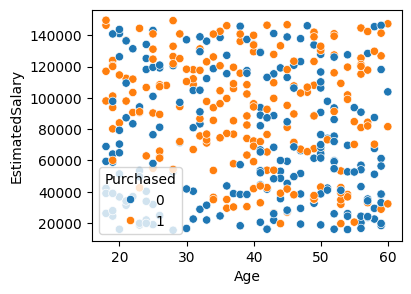

In [5]:
# lets create a graph and see if the data is applicable for logistic regression i.e its linearly separable
plt.figure(figsize=(4, 3))
sns.scatterplot(x='Age', y='EstimatedSalary', hue='Purchased', data=dataset)
plt.show()

In [6]:
# we can clearly see the data is not linearly seperable 

# 1) simple logistic regression
x = dataset.iloc[: , : -1]
y = dataset["Purchased"]

from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [7]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(x_train,y_train)
lr.score(x_test,y_test)

0.5875

C:\Users\junai\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


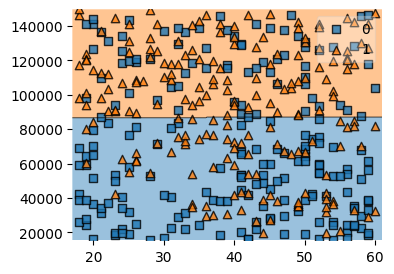

In [8]:
# now we want to see the decision boundary using ml extend library
from mlxtend.plotting import plot_decision_regions

plt.figure(figsize=(4, 3))
plot_decision_regions(x.to_numpy(), y.to_numpy(), clf=lr)
plt.show()

In [9]:
#we can see the accuracy is low and also not that much linearly seperable and also we can see miss classification

# now ill give it polynomial feature and see the result

In [10]:
#2) using polynomial feature
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# load data set
dataset = pd.read_csv(r'C:\Users\junai\Desktop\coding\ML\subscription_data.csv')
dataset.head()

,Age,EstimatedSalary,Purchased
0,56,115235,1
1,46,89740,1
2,32,131352,1
3,60,81617,1
4,25,31896,0


In [34]:
x = dataset.iloc[: , : -1]
y = dataset["Purchased"]

from sklearn.preprocessing import PolynomialFeatures

pf = PolynomialFeatures(degree=1) # increase or decrese degree to increase accuracy
pf.fit(x)
x = pd.DataFrame(pf.transform(x)) 

In [54]:
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=27)

In [55]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(x_train,y_train)
lr.score(x_test,y_test)

0.6875

In [61]:
x.shape

(400, 3)

In [ ]:
# equation

-----

### Practical implementation of the logistic regression algorithm

#### Logistic Regression multiclass classification